# The MNIST example

`examples/g_experiments/g3_mnist.py` trains a small network on handwritten digits with numpy alone. This notebook uses its own functions on a tiny made-up set of 28 by 28 pictures (ten blob patterns plus noise), so it needs no download and runs in a second or two. It writes the pictures as gzipped IDX files, reads them back with the example's reader, trains for a few hundred steps and plots the loss and the accuracy.

In [1]:
# Standard library
import gzip
import io
import struct
import sys
from pathlib import Path

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
from IPython import display as ipython_display
from matplotlib.figure import Figure

In [3]:
# The example is a script, so put its folder on the path
import element_51

ROOT = Path(element_51.__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT / "examples" / "g_experiments"))

In [4]:
# Local libraries
import g3_mnist

In [5]:
SEED = 51
SIDE = 28
CLASSES = 10
TRAIN = 1000
TEST = 200
STEPS = 300
BATCH = 100
RATE = 0.1
HIDDEN = 32
ENOUGH = 0.9
NOISE = 40
OUT = Path("__data__")
OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def show(figure: Figure) -> None:
    """Show a figure inline as a small PNG."""
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=70, bbox_inches="tight")
    plt.close(figure)
    ipython_display.display(ipython_display.Image(data=buffer.getvalue()))

## Made-up digits

Each class is a bright 6 by 6 blob at its own place on the grid, plus noise. A network should learn that quickly.

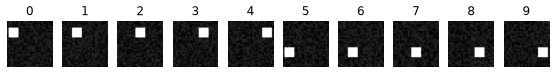

In [6]:
def blobs(count: int) -> tuple[np.ndarray, np.ndarray]:
    """Draw `count` pictures and their labels.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Pixels, one row per picture, and the labels.
    """
    labels = rng.integers(0, CLASSES, count)
    pixels = rng.integers(0, NOISE, (count, SIDE, SIDE))
    for index, label in enumerate(labels):
        row, column = divmod(int(label), 5)
        pixels[
            index, row * 12 + 4 : row * 12 + 10, column * 5 + 1 : column * 5 + 7
        ] = 255
    return pixels.reshape(count, SIDE * SIDE).astype(np.uint8), labels.astype(
        np.uint8
    )


train_images, train_labels = blobs(TRAIN)
test_images, test_labels = blobs(TEST)
figure, axes = plt.subplots(1, CLASSES, figsize=(10, 1.2))
for digit, axis in enumerate(axes):
    first = int(np.flatnonzero(train_labels == digit)[0])
    axis.imshow(train_images[first].reshape(SIDE, SIDE), cmap="gray")
    axis.set_title(str(digit))
    axis.axis("off")
show(figure)
assert train_images.shape == (TRAIN, SIDE * SIDE)

## Write and read the IDX files

In [7]:
def write_idx(
    path: Path, magic: int, shape: tuple[int, ...], body: bytes
) -> None:
    """Write a gzipped IDX file: a magic number, the sizes, the bytes."""
    head = struct.pack(">I", magic) + b"".join(
        struct.pack(">I", n) for n in shape
    )
    path.write_bytes(gzip.compress(head + body))


write_idx(
    OUT / "images.gz", 0x0803, (TRAIN, SIDE, SIDE), train_images.tobytes()
)
write_idx(OUT / "labels.gz", 0x0801, (TRAIN,), train_labels.tobytes())
images = g3_mnist.load_images(OUT / "images.gz")
labels = g3_mnist.load_labels(OUT / "labels.gz")
print(images.shape, labels.shape)
assert images.shape == (TRAIN, SIDE * SIDE)
assert (images == train_images).all()
assert (labels == train_labels).all()

(1000, 784) (1000,)


## Train

One step is a batch of pictures: find the loss and the gradients, then step downhill. The accuracy is measured on the test pictures every 10 steps.

In [8]:
weights = g3_mnist.init_weights(HIDDEN, np.random.default_rng(SEED))
losses: list[float] = []
accuracies: list[float] = []
for step in range(STEPS):
    start = (step * BATCH) % TRAIN
    batch = g3_mnist.to_floats(images[start : start + BATCH])
    loss, grads = g3_mnist.loss_and_gradients(
        weights, batch, labels[start : start + BATCH]
    )
    g3_mnist.apply_gradients(weights, grads, RATE)
    losses.append(loss)
    if step % 10 == 0:
        accuracies.append(g3_mnist.accuracy(weights, test_images, test_labels))
print(
    f"loss {losses[0]:.3f} to {losses[-1]:.3f}, accuracy {accuracies[-1]:.3f}"
)

loss 2.370 to 0.005, accuracy 1.000


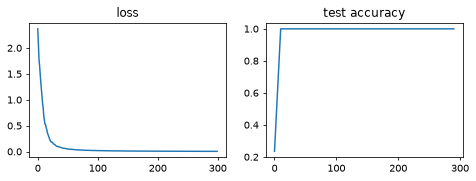

In [9]:
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 2.5))
left.plot(losses)
left.set_title("loss")
right.plot(range(0, STEPS, 10), accuracies)
right.set_title("test accuracy")
show(figure)
assert losses[-1] < losses[0]
assert accuracies[-1] > ENOUGH

## The node and the job

`build_app()` makes the graph the example serves. The notebook only checks that it builds with the three nodes and their links.

In [10]:
app = g3_mnist.build_app()
names = [placed.node_type for placed in app.graph.nodes]
print(names, len(app.graph.links), "links")
assert names == ["MnistSample", "Train", "Plot"]

['MnistSample', 'Train', 'Plot'] 3 links
